In [1]:
import pandas as pd

# 1. Define the file path
file_path = 'PS_20174392719_1491204439457_log.csv'

# 2. Load the entire dataset into Pandas
print("Loading the CSV...")
df = pd.read_csv(file_path)

# 3. Sample exactly 1,000 fraud rows and 4,000 normal rows
# Using random_state=42 ensures we get the exact same random sample every time we run this cell
fraud_sample = df[df['isFraud'] == 1].sample(n=1000, random_state=42)
normal_sample = df[df['isFraud'] == 0].sample(n=4000, random_state=42)

# 4. Combine them into a single dataframe (5,000 rows total)
sampled_df = pd.concat([fraud_sample, normal_sample])

# 5. Shuffle the combined dataset so the fraud rows aren't all stuck at the top
sampled_df = sampled_df.sample(frac=1, random_state=42).reset_index(drop=True)

# 6. Save the lightweight dataset for the rest of the project
sampled_df.to_csv('sampled_transactions.csv', index=False)

print(f"Success! Saved {len(sampled_df)} rows to sampled_transactions.csv.")

Loading the CSV...
Success! Saved 5000 rows to sampled_transactions.csv.


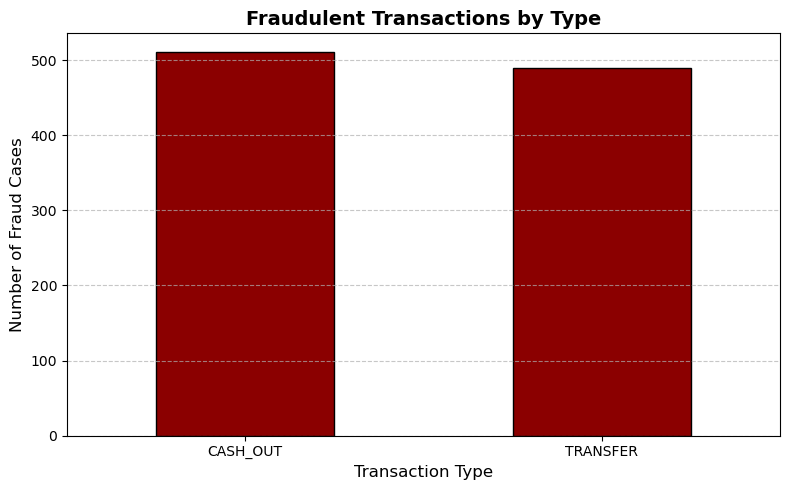

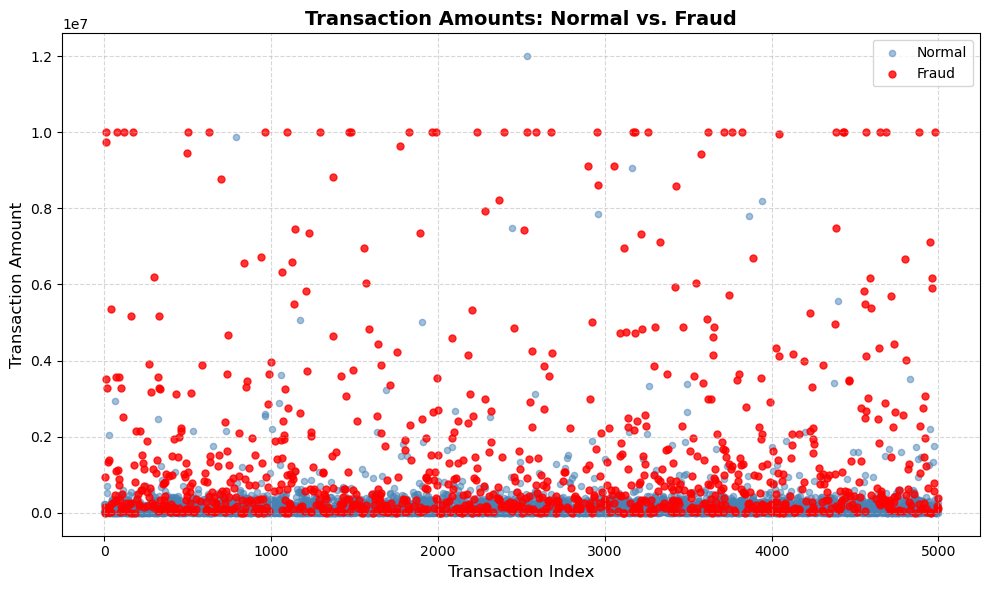

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the newly created lightweight dataset
df = pd.read_csv('sampled_transactions.csv')

# ---------------------------------------------------------
# Chart 1: Bar Chart of Fraud by Transaction Type
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))

# Filter for only fraudulent transactions and count occurrences of each type
fraud_data = df[df['isFraud'] == 1]['type'].value_counts()

# Plotting
fraud_data.plot(kind='bar', color='darkred', edgecolor='black')
plt.title('Fraudulent Transactions by Type', fontsize=14, fontweight='bold')
plt.xlabel('Transaction Type', fontsize=12)
plt.ylabel('Number of Fraud Cases', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Save as PNG
plt.savefig('fraud_by_type.png', dpi=300)
plt.show()

# ---------------------------------------------------------
# Chart 2: Scatter Plot of Transaction Amounts
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))

# Separate data into normal and fraud for color coding
normal = df[df['isFraud'] == 0]
fraud = df[df['isFraud'] == 1]

# Plotting normal transactions first (blue), then fraud on top (red)
plt.scatter(normal.index, normal['amount'], color='steelblue', alpha=0.5, label='Normal', s=20)
plt.scatter(fraud.index, fraud['amount'], color='red', alpha=0.8, label='Fraud', s=25)

plt.title('Transaction Amounts: Normal vs. Fraud', fontsize=14, fontweight='bold')
plt.xlabel('Transaction Index', fontsize=12)
plt.ylabel('Transaction Amount', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Save as PNG
plt.savefig('transaction_amounts.png', dpi=300)
plt.show()